In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_selection import f_classif
from sklearn.metrics import (accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix,
    roc_curve, roc_auc_score, classification_report)

In [2]:
df = pd.read_csv("C:\\Users\\Dell\\Downloads\\10. heart_attack_dataset.csv")

In [3]:
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")
print(df.head(3))
print()

Rows    : 1000
Columns : 11
   Age  Cholesterol  BloodPressure   BMI  Smoking  Diabetes  ExerciseHours  \
0   58          183            175  22.7        1         1            0.5   
1   71          241            177  20.7        1         1            0.5   
2   48          244            142  35.8        1         0            6.9   

   FamilyHistory  AlcoholUnits  StressLevel  HeartAttack  
0              0          17.7            1            1  
1              0          17.9            1            1  
2              0           6.7            4            1  



In [4]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Age              0
Cholesterol      0
BloodPressure    0
BMI              0
Smoking          0
Diabetes         0
ExerciseHours    0
FamilyHistory    0
AlcoholUnits     0
StressLevel      0
HeartAttack      0
dtype: int64


In [5]:
print(f"Duplicate rows : {df.duplicated().sum()}")

Duplicate rows : 0


In [6]:
print("Target distribution:")
print(df['HeartAttack'].value_counts())
print()

Target distribution:
HeartAttack
1    774
0    226
Name: count, dtype: int64



In [7]:
X = df.drop('HeartAttack', axis=1)  # all columns except target
y = df['HeartAttack']               # only target column

print(f"X shape : {X.shape}")
print(f"y shape : {y.shape}")
print()

X shape : (1000, 10)
y shape : (1000,)



In [8]:
f_scores, p_values = f_classif(X, y)

feature_scores = pd.DataFrame({
    'Feature' : X.columns,
    'F-Score' : f_scores.round(2),
    'P-Value' : p_values.round(4),
    'Keep'    : ['Yes' if p < 0.05 else 'No' for p in p_values]
}).sort_values('F-Score', ascending=False)

print(feature_scores.to_string(index=False))

      Feature  F-Score  P-Value Keep
          Age   206.36   0.0000  Yes
  Cholesterol    95.52   0.0000  Yes
          BMI    73.62   0.0000  Yes
BloodPressure    57.43   0.0000  Yes
ExerciseHours    30.62   0.0000  Yes
      Smoking    23.67   0.0000  Yes
 AlcoholUnits    15.14   0.0001  Yes
     Diabetes    12.07   0.0005  Yes
  StressLevel    11.16   0.0009  Yes
FamilyHistory     7.75   0.0055  Yes


In [9]:
selected = feature_scores[feature_scores['Keep'] == 'Yes']['Feature'].tolist()
X = X[selected]

print(f"\nSelected {len(selected)} features: {selected}")
print()


Selected 10 features: ['Age', 'Cholesterol', 'BMI', 'BloodPressure', 'ExerciseHours', 'Smoking', 'AlcoholUnits', 'Diabetes', 'StressLevel', 'FamilyHistory']



In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size    = 0.2,
    random_state = 42,
    stratify     = y
)

print(f"Train : {X_train.shape[0]} samples")
print(f"Test  : {X_test.shape[0]} samples")
print()

Train : 800 samples
Test  : 200 samples



In [11]:
scaler         = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Scaling done")
print(f"Train mean (first 3): {X_train_scaled[:, 0].mean():.3f}")
print(f"Train std  (first 3): {X_train_scaled[:, 0].std():.3f}")
print()

Scaling done
Train mean (first 3): -0.000
Train std  (first 3): 1.000



In [12]:
model = LogisticRegression(max_iter=100, random_state=42)
model.fit(X_train_scaled, y_train)

print("Model trained with default parameters")
print(f"  C      : {model.C}")
print(f"  Solver : {model.solver}")
print()

Model trained with default parameters
  C      : 1.0
  Solver : lbfgs



In [13]:
y_pred       = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred):.4f}")
print(f"AUC Score : {roc_auc_score(y_test, y_pred_proba):.4f}")
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print()
print("Classification Report:")
print(classification_report(y_test, y_pred,
      target_names=['No Attack', 'Heart Attack']))

Accuracy  : 0.9350
Precision : 0.9437
Recall    : 0.9742
F1 Score  : 0.9587
AUC Score : 0.9838

Confusion Matrix:
[[ 36   9]
 [  4 151]]

Classification Report:
              precision    recall  f1-score   support

   No Attack       0.90      0.80      0.85        45
Heart Attack       0.94      0.97      0.96       155

    accuracy                           0.94       200
   macro avg       0.92      0.89      0.90       200
weighted avg       0.93      0.94      0.93       200



In [14]:
fpr1, tpr1, _ = roc_curve(y_test, y_pred_proba)
auc1          = roc_auc_score(y_test, y_pred_proba)

In [15]:
param_grid = {
    'C'            : [0.01, 0.1, 1, 10, 100],
    'solver'       : ['lbfgs', 'liblinear'],
    'max_iter'     : [500, 1000],
    'class_weight' : [None, 'balanced']
}

In [16]:
grid = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid,
    cv      = 5,          # 5-fold cross validation
    scoring = 'roc_auc',  # optimize for AUC
    n_jobs  = -1          # use all CPU cores
)

In [17]:
grid.fit(X_train_scaled, y_train)

print(f"Best Parameters : {grid.best_params_}")
print(f"Best CV AUC     : {grid.best_score_:.4f}")
print()

best_model = grid.best_estimator_

Best Parameters : {'C': 100, 'class_weight': 'balanced', 'max_iter': 500, 'solver': 'lbfgs'}
Best CV AUC     : 0.9892



In [18]:
y_pred2       = best_model.predict(X_test_scaled)
y_pred_proba2 = best_model.predict_proba(X_test_scaled)[:, 1]

print(f"Accuracy  : {accuracy_score(y_test, y_pred2):.4f}")
print(f"Precision : {precision_score(y_test, y_pred2):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred2):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred2):.4f}")
print(f"AUC Score : {roc_auc_score(y_test, y_pred_proba2):.4f}")
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred2))
print()
print("Classification Report:")
print(classification_report(y_test, y_pred2,
      target_names=['No Attack', 'Heart Attack']))

Accuracy  : 0.9500
Precision : 0.9801
Recall    : 0.9548
F1 Score  : 0.9673
AUC Score : 0.9848

Confusion Matrix:
[[ 42   3]
 [  7 148]]

Classification Report:
              precision    recall  f1-score   support

   No Attack       0.86      0.93      0.89        45
Heart Attack       0.98      0.95      0.97       155

    accuracy                           0.95       200
   macro avg       0.92      0.94      0.93       200
weighted avg       0.95      0.95      0.95       200



In [19]:
fpr2, tpr2, _ = roc_curve(y_test, y_pred_proba2)
auc2          = roc_auc_score(y_test, y_pred_proba2)

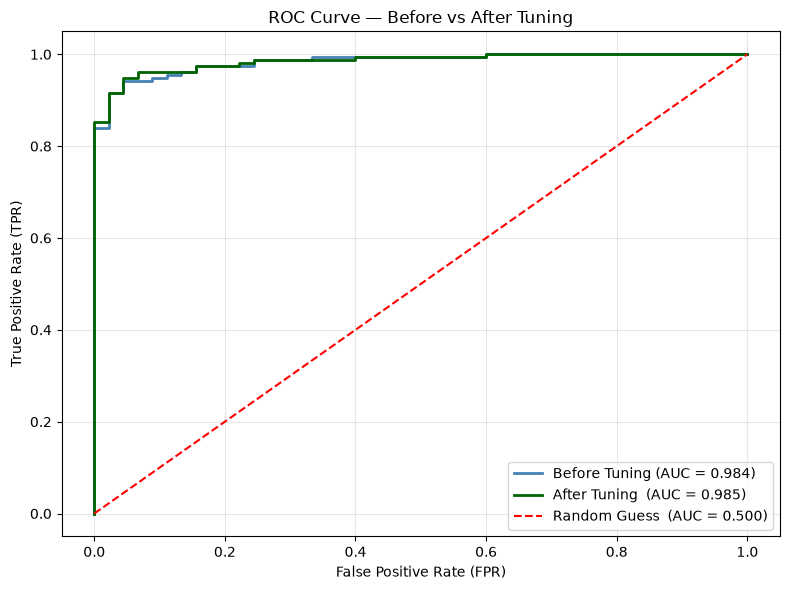

ROC curve saved



In [20]:
plt.figure(figsize=(8, 6))

plt.plot(fpr1, tpr1, color='steelblue', lw=2,
         label=f'Before Tuning (AUC = {auc1:.3f})')

plt.plot(fpr2, tpr2, color='darkgreen', lw=2,
         label=f'After Tuning  (AUC = {auc2:.3f})')

plt.plot([0, 1], [0, 1], 'r--', lw=1.5,
         label='Random Guess  (AUC = 0.500)')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve — Before vs After Tuning')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve_simple.png', dpi=150)
plt.show()
print("ROC curve saved")
print()

In [21]:
joblib.dump(best_model, 'best_model.pkl')
joblib.dump(scaler,     'best_scaler.pkl')

print("best_model.pkl  saved")
print("best_scaler.pkl saved")
print()

best_model.pkl  saved
best_scaler.pkl saved



In [22]:
loaded_model  = joblib.load('best_model.pkl')
loaded_scaler = joblib.load('best_scaler.pkl')

print(f"Model  loaded : {type(loaded_model).__name__}")
print(f"Scaler loaded : {type(loaded_scaler).__name__}")
print(f"C      : {loaded_model.C}")
print(f"Solver : {loaded_model.solver}")
print()

Model  loaded : LogisticRegression
Scaler loaded : StandardScaler
C      : 100
Solver : lbfgs



In [23]:
new_data = pd.DataFrame({
    'Age'           : [22,  45,  55,  63,  70 ],
    'Cholesterol'   : [170, 210, 280, 320, 345 ],
    'BloodPressure' : [108, 130, 150, 172, 175 ],
    'BMI'           : [21.5, 27.0, 31.5, 38.0, 42.0],
    'Smoking'       : [0,   0,   1,   1,   1  ],
    'Diabetes'      : [0,   0,   0,   1,   1  ],
    'ExerciseHours' : [8.0, 4.5, 2.0, 1.0, 0.5],
    'FamilyHistory' : [0,   1,   0,   1,   1  ],
    'AlcoholUnits'  : [2.0, 8.0, 12.0, 17.0, 19.0],
    'StressLevel'   : [2,   5,   6,   8,   9  ]
})

In [24]:
new_data = new_data[selected]

In [25]:
new_scaled = loaded_scaler.transform(new_data)

In [26]:
predictions  = loaded_model.predict(new_scaled)
probabilities = loaded_model.predict_proba(new_scaled)[:, 1]

In [27]:
print(f"{'Patient':<10} {'Probability':<15} {'Prediction'}")
print("-" * 40)
for i in range(len(predictions)):
    result = "HEART ATTACK" if predictions[i] == 1 else "NO ATTACK"
    print(f"Patient {i+1:<3} {probabilities[i]:<15.3f} {result}")

Patient    Probability     Prediction
----------------------------------------
Patient 1   0.000           NO ATTACK
Patient 2   0.024           NO ATTACK
Patient 3   1.000           HEART ATTACK
Patient 4   1.000           HEART ATTACK
Patient 5   1.000           HEART ATTACK
